# Lejebolig · lokal LLM + RAG

Anden halvdel af sammenligningsøvelsen. Opgaven er den samme som i `../regression/linear_regression.ipynb`: estimér den annoncerede månedlige husleje i kroner ud fra lejlighedens areal i m². Her er det den lokale LLM (`rag-llm`), der forudsiger, og ikke en regressionsmodel.

- **Samme testcases.** Kolonnen `split` i `../regression/dataset.csv` bestemmer de 6 testrækker.
- **RAG-samlingen har kun træningsrækker.** Testrækkernes husleje læses først i trin 5, hvor vi måler fejlen.
- **LLM'en får kun tekst.** Den kalder ikke regressionsmodellen og kører ingen kode.

Ollama skal køre med `rag-llm` og `bge-m3` (se `ollama/README.md`). Funktionerne ligger i `llm_rag_predict.py`, som også kan køres som script.

In [1]:
import csv
import sqlite3
import sys
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parents[1]  # notebooken køres fra experiments/experiment_rag/
sys.path.insert(0, str(ROOT))

from experiments.experiment_rag.llm_rag_predict import (
    DEFAULT_DATABASE, DEFAULT_LLM, DEFAULT_TOP_K, RAG_INSTRUCTION, SYSTEM_PROMPT,
    ask_llm, build_collection, kroner, load_dataset, plain_prompt, query_text, rag_prompt, retrieve,
)
from rag.embeddings import DEFAULT_MODEL as EMBED_MODEL
from rag.embeddings import DEFAULT_OLLAMA_URL as OLLAMA_URL

## 1. Læs data

`load_dataset()` returnerer træningsrækkerne og kun arealet fra testrækkerne.

In [2]:
train, test_areas = load_dataset()
train_by_id = {row["id"]: row for row in train}

print(f"Træningsrækker til RAG-samlingen: {len(train)}")
print(f"Testinput (m²): {', '.join(test_areas)}")

Træningsrækker til RAG-samlingen: 294
Testinput (m²): 85, 117, 99, 141, 60, 31


## 2. Byg RAG-samlingen

Hver træningsrække bliver til én kort tekst. Teksten embeddes med `bge-m3` og gemmes i `.cache/rag/rent_examples.sqlite3`. Formatet er det samme som i `rag.ingest`, men filen er separat, så eksemplerne ikke blandes med vidensbiblioteket.

In [3]:
build_collection(train, DEFAULT_DATABASE, EMBED_MODEL, OLLAMA_URL)

with closing(sqlite3.connect(DEFAULT_DATABASE)) as connection:
    for chunk_id, text in connection.execute("SELECT id, text FROM rag_chunks LIMIT 3"):
        print(f"{chunk_id} → {text}")

RAG-samling: 294 træningsrækker gemt i .cache/rag/rent_examples.sqlite3


dataset.csv:2 → Apartment in Copenhagen, 26 m². Monthly rent: 7650 DKK.
dataset.csv:3 → Apartment in Copenhagen, 156 m². Monthly rent: 26012 DKK.
dataset.csv:4 → Apartment in Copenhagen, 70 m². Monthly rent: 14995 DKK.


## 3. Hent eksempler (retrieval)

Søgeteksten for en testcase embeddes med samme model. Alle eksempler rangeres efter cosine similarity, og de 5 mest lignende sendes med til LLM'en. Den sidste kolonne viser, hvor langt det hentede areal ligger fra testarealet.

In [4]:
retrieved = {}
for area in test_areas:
    hits = retrieve(DEFAULT_DATABASE, query_text(area), DEFAULT_TOP_K, OLLAMA_URL)
    retrieved[area] = hits
    rows = ["| # | Cosine | Hentet tekst | Type | Arealafstand |", "|---:|---:|---|---|---:|"]
    for rank, (similarity, chunk_id, text) in enumerate(hits, start=1):
        row = train_by_id[chunk_id]
        kind = "rigtig" if row["data_type"] == "real" else "genereret"
        distance = abs(float(row["area_m2"]) - float(area))
        rows.append(f"| {rank} | {similarity:.4f} | {text} | {kind} | {distance:g} m² |")
    display(Markdown(f"#### Testcase {area} m²\n\nSøgetekst: `{query_text(area)}`\n\n" + "\n".join(rows)))

#### Testcase 85 m²

Søgetekst: `Apartment in Copenhagen, 85 m². Monthly rent:`

| # | Cosine | Hentet tekst | Type | Arealafstand |
|---:|---:|---|---|---:|
| 1 | 0.9070 | Apartment in Copenhagen, 88 m². Monthly rent: 19850 DKK. | genereret | 3 m² |
| 2 | 0.8768 | Apartment in Copenhagen, 35 m². Monthly rent: 9100 DKK. | genereret | 50 m² |
| 3 | 0.8730 | Apartment in Copenhagen, 83 m². Monthly rent: 15250 DKK. | genereret | 2 m² |
| 4 | 0.8712 | Apartment in Copenhagen, 155 m². Monthly rent: 25850 DKK. | genereret | 70 m² |
| 5 | 0.8710 | Apartment in Copenhagen, 83 m². Monthly rent: 15800 DKK. | genereret | 2 m² |

#### Testcase 117 m²

Søgetekst: `Apartment in Copenhagen, 117 m². Monthly rent:`

| # | Cosine | Hentet tekst | Type | Arealafstand |
|---:|---:|---|---|---:|
| 1 | 0.8799 | Apartment in Copenhagen, 115 m². Monthly rent: 18800 DKK. | genereret | 2 m² |
| 2 | 0.8784 | Apartment in Copenhagen, 115 m². Monthly rent: 21000 DKK. | genereret | 2 m² |
| 3 | 0.8732 | Apartment in Copenhagen, 116 m². Monthly rent: 21150 DKK. | genereret | 1 m² |
| 4 | 0.8726 | Apartment in Copenhagen, 113 m². Monthly rent: 20000 DKK. | genereret | 4 m² |
| 5 | 0.8712 | Apartment in Copenhagen, 111 m². Monthly rent: 19150 DKK. | genereret | 6 m² |

#### Testcase 99 m²

Søgetekst: `Apartment in Copenhagen, 99 m². Monthly rent:`

| # | Cosine | Hentet tekst | Type | Arealafstand |
|---:|---:|---|---|---:|
| 1 | 0.8824 | Apartment in Copenhagen, 89 m². Monthly rent: 19995 DKK. | rigtig | 10 m² |
| 2 | 0.8796 | Apartment in Copenhagen, 49 m². Monthly rent: 9600 DKK. | genereret | 50 m² |
| 3 | 0.8745 | Apartment in Copenhagen, 49 m². Monthly rent: 10850 DKK. | genereret | 50 m² |
| 4 | 0.8730 | Apartment in Copenhagen, 100 m². Monthly rent: 16700 DKK. | genereret | 1 m² |
| 5 | 0.8721 | Apartment in Copenhagen, 98 m². Monthly rent: 18900 DKK. | genereret | 1 m² |

#### Testcase 141 m²

Søgetekst: `Apartment in Copenhagen, 141 m². Monthly rent:`

| # | Cosine | Hentet tekst | Type | Arealafstand |
|---:|---:|---|---|---:|
| 1 | 0.9357 | Apartment in Copenhagen, 141 m². Monthly rent: 23700 DKK. | genereret | 0 m² |
| 2 | 0.8837 | Apartment in Copenhagen, 142 m². Monthly rent: 22550 DKK. | genereret | 1 m² |
| 3 | 0.8828 | Apartment in Copenhagen, 140 m². Monthly rent: 27100 DKK. | genereret | 1 m² |
| 4 | 0.8812 | Apartment in Copenhagen, 142 m². Monthly rent: 24800 DKK. | genereret | 1 m² |
| 5 | 0.8797 | Apartment in Copenhagen, 41 m². Monthly rent: 10700 DKK. | genereret | 100 m² |

#### Testcase 60 m²

Søgetekst: `Apartment in Copenhagen, 60 m². Monthly rent:`

| # | Cosine | Hentet tekst | Type | Arealafstand |
|---:|---:|---|---|---:|
| 1 | 0.9318 | Apartment in Copenhagen, 60 m². Monthly rent: 13350 DKK. | genereret | 0 m² |
| 2 | 0.8693 | Apartment in Copenhagen, 156 m². Monthly rent: 26000 DKK. | genereret | 96 m² |
| 3 | 0.8656 | Apartment in Copenhagen, 62 m². Monthly rent: 16200 DKK. | genereret | 2 m² |
| 4 | 0.8649 | Apartment in Copenhagen, 61 m². Monthly rent: 13450 DKK. | genereret | 1 m² |
| 5 | 0.8648 | Apartment in Copenhagen, 156 m². Monthly rent: 26012 DKK. | rigtig | 96 m² |

#### Testcase 31 m²

Søgetekst: `Apartment in Copenhagen, 31 m². Monthly rent:`

| # | Cosine | Hentet tekst | Type | Arealafstand |
|---:|---:|---|---|---:|
| 1 | 0.9218 | Apartment in Copenhagen, 31 m². Monthly rent: 8550 DKK. | genereret | 0 m² |
| 2 | 0.8794 | Apartment in Copenhagen, 29 m². Monthly rent: 6800 DKK. | genereret | 2 m² |
| 3 | 0.8734 | Apartment in Copenhagen, 29 m². Monthly rent: 7700 DKK. | genereret | 2 m² |
| 4 | 0.8676 | Apartment in Copenhagen, 32 m². Monthly rent: 12050 DKK. | genereret | 1 m² |
| 5 | 0.8644 | Apartment in Copenhagen, 30 m². Monthly rent: 8400 DKK. | genereret | 1 m² |

Grafen viser arealet på de hentede eksempler for hver testcase. Ligger et punkt på den stiplede linje, har eksemplet samme areal som testcasen. Embeddingmodellen sammenligner tekst og ikke talværdier, så eksempler med lignende cifre kan blive hentet, selv om arealet er langt fra.

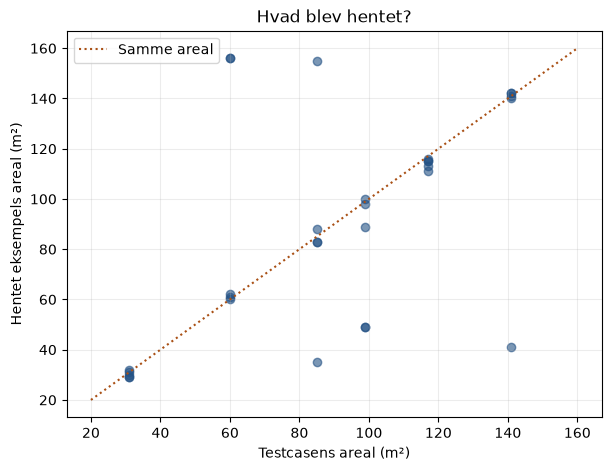

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.6), layout="constrained")
for area, hits in retrieved.items():
    hit_areas = [float(train_by_id[chunk_id]["area_m2"]) for _, chunk_id, _ in hits]
    ax.scatter([float(area)] * len(hit_areas), hit_areas, color="#245285", alpha=0.6)
ax.plot([20, 160], [20, 160], color="#a95015", linestyle="dotted", label="Samme areal")
ax.set(title="Hvad blev hentet?", xlabel="Testcasens areal (m²)", ylabel="Hentet eksempels areal (m²)")
ax.grid(alpha=0.24)
ax.legend()
plt.show()

## 4. Spørg den lokale LLM

Systemprompten bruger 4T: **Traits** (erfaren vurderingsmand på det københavnske lejemarked), **Task** (estimér lejen ud fra arealet, uden aconto og depositum), **Tone** (præcis, ingen forklaring) og **Target** (et program læser svaret, så kun JSON). Med RAG kommer en sætning mere på: brug eksemplerne fra træningsdata.

Ollamas structured output (`format`) tvinger svaret til JSON med ét heltal. `temperature 0` og `seed 42` gør kørslen gentagelig. Vi spørger også uden RAG for at se, hvad retrieval ændrer.

In [6]:
rag_system = f"{SYSTEM_PROMPT} {RAG_INSTRUCTION}"
print("Systemprompt med RAG:\n" + rag_system + "\n")
print("Brugerprompt med RAG for første testcase:\n" + rag_prompt(test_areas[0], retrieved[test_areas[0]]) + "\n")
print("Brugerprompt uden RAG:\n" + plain_prompt(test_areas[0]))

Systemprompt med RAG:
You are an experienced rental valuer for the Copenhagen apartment market. Estimate the advertised monthly rent in Danish kroner (DKK) for one apartment from its floor area. Rent means the advertised monthly rent without utilities (aconto) and without deposit. Be precise and factual and do not explain your answer. A program reads your reply and compares it with other estimates, so reply only with JSON in the form {"monthly_rent_dkk": <integer>}. Base your estimate on the reference examples from the training data.

Brugerprompt med RAG for første testcase:
Reference examples (training data):
- Apartment in Copenhagen, 88 m². Monthly rent: 19850 DKK.
- Apartment in Copenhagen, 35 m². Monthly rent: 9100 DKK.
- Apartment in Copenhagen, 83 m². Monthly rent: 15250 DKK.
- Apartment in Copenhagen, 155 m². Monthly rent: 25850 DKK.
- Apartment in Copenhagen, 83 m². Monthly rent: 15800 DKK.

Apartment to estimate: 85 m². What is the monthly rent in DKK?

Brugerprompt uden RAG

In [7]:
llm_rag, llm_plain = {}, {}
rows = [
    "| Areal | LLM + RAG | Råt svar | Samme leje som hentet eksempel | LLM uden RAG | Råt svar |",
    "|---:|---:|---|---|---:|---|",
]
for area in test_areas:
    llm_rag[area], rag_answer = ask_llm(rag_prompt(area, retrieved[area]), rag_system, DEFAULT_LLM, OLLAMA_URL)
    llm_plain[area], plain_answer = ask_llm(plain_prompt(area), SYSTEM_PROMPT, DEFAULT_LLM, OLLAMA_URL)
    hit_rents = [int(train_by_id[chunk_id]["monthly_rent_dkk"]) for _, chunk_id, _ in retrieved[area]]
    copied = ", ".join(f"#{rank}" for rank, rent in enumerate(hit_rents, start=1) if rent == llm_rag[area]) or "nej"
    rows.append(
        f"| {area} m² | {kroner(llm_rag[area])} | `{' '.join(rag_answer.split())}` | {copied} "
        f"| {kroner(llm_plain[area])} | `{' '.join(plain_answer.split())}` |"
    )
display(Markdown("\n".join(rows)))

| Areal | LLM + RAG | Råt svar | Samme leje som hentet eksempel | LLM uden RAG | Råt svar |
|---:|---:|---|---|---:|---|
| 85 m² | 19.850 kr. | `{"monthly_rent_dkk": 19850 }` | #1 | 85 kr. | `{"monthly_rent_dkk": 85}` |
| 117 m² | 18.800 kr. | `{"monthly_rent_dkk": 18800 }` | #1 | 117 kr. | `{"monthly_rent_dkk": 117}` |
| 99 m² | 19.995 kr. | `{"monthly_rent_dkk": 19995}` | #1 | 99 kr. | `{"monthly_rent_dkk": 99 }` |
| 141 m² | 23.700 kr. | `{"monthly_rent_dkk": 23700 }` | #1 | 141 kr. | `{"monthly_rent_dkk": 141}` |
| 60 m² | 13.350 kr. | `{"monthly_rent_dkk": 13350 }` | #1 | 60 kr. | `{"monthly_rent_dkk": 60}` |
| 31 m² | 8.400 kr. | `{"monthly_rent_dkk": 8400 }` | #5 | 31 kr. | `{"monthly_rent_dkk": 31}` |

## 5. Sammenlign med regressionen

Først nu læses testrækkernes faktiske husleje, og kun for at måle fejlen. Regressionens forudsigelser kommer fra `../regression/predictions_regression.csv`. Kør `train_linear_regression.py` først, hvis filen mangler.

Fejl er |forudsagt − faktisk|. MAE er gennemsnittet af fejlene over testcases.

In [8]:
with (ROOT / "experiments" / "regression" / "dataset.csv").open(encoding="utf-8", newline="") as file:
    test = [row for row in csv.DictReader(file) if row["split"] == "test"]
with (ROOT / "experiments" / "regression" / "predictions_regression.csv").open(encoding="utf-8", newline="") as file:
    regression = {row["area_m2"]: float(row["predicted_rent_dkk"]) for row in csv.DictReader(file)}

methods = {"Regression": regression, "LLM + RAG": llm_rag, "LLM uden RAG": llm_plain}
errors = {name: [] for name in methods}
rows = [
    "| Areal | Type | Faktisk | " + " | ".join(f"{name} | Fejl" for name in methods) + " |",
    "|---:|---|---:|" + "---:|---:|" * len(methods),
]
for row in sorted(test, key=lambda row: float(row["area_m2"])):
    area, actual = row["area_m2"], float(row["monthly_rent_dkk"])
    cells = [f"{area} m²", "rigtig" if row["data_type"] == "real" else "genereret", kroner(round(actual))]
    for name, predictions in methods.items():
        error = abs(predictions[area] - actual)
        errors[name].append(error)
        cells += [kroner(round(predictions[area])), kroner(round(error))]
    rows.append("| " + " | ".join(cells) + " |")
mae_cells = ["**MAE**", "", ""]
for name in methods:
    mae_cells += ["", f"**{kroner(round(sum(errors[name]) / len(errors[name])))}**"]
rows.append("| " + " | ".join(mae_cells) + " |")
display(Markdown("\n".join(rows)))

| Areal | Type | Faktisk | Regression | Fejl | LLM + RAG | Fejl | LLM uden RAG | Fejl |
|---:|---|---:|---:|---:|---:|---:|---:|---:|
| 31 m² | genereret | 9.300 kr. | 9.178 kr. | 122 kr. | 8.400 kr. | 900 kr. | 31 kr. | 9.269 kr. |
| 60 m² | genereret | 13.600 kr. | 13.210 kr. | 390 kr. | 13.350 kr. | 250 kr. | 60 kr. | 13.540 kr. |
| 85 m² | rigtig | 14.500 kr. | 16.686 kr. | 2.186 kr. | 19.850 kr. | 5.350 kr. | 85 kr. | 14.415 kr. |
| 99 m² | genereret | 16.550 kr. | 18.633 kr. | 2.083 kr. | 19.995 kr. | 3.445 kr. | 99 kr. | 16.451 kr. |
| 117 m² | rigtig | 20.486 kr. | 21.136 kr. | 650 kr. | 18.800 kr. | 1.686 kr. | 117 kr. | 20.369 kr. |
| 141 m² | genereret | 24.900 kr. | 24.473 kr. | 427 kr. | 23.700 kr. | 1.200 kr. | 141 kr. | 24.759 kr. |
| **MAE** |  |  |  | **976 kr.** |  | **2.138 kr.** |  | **16.467 kr.** |

LLM uden RAG er udeladt af grafen, fordi dens svar ligger langt under de andre og ville presse skalaen.

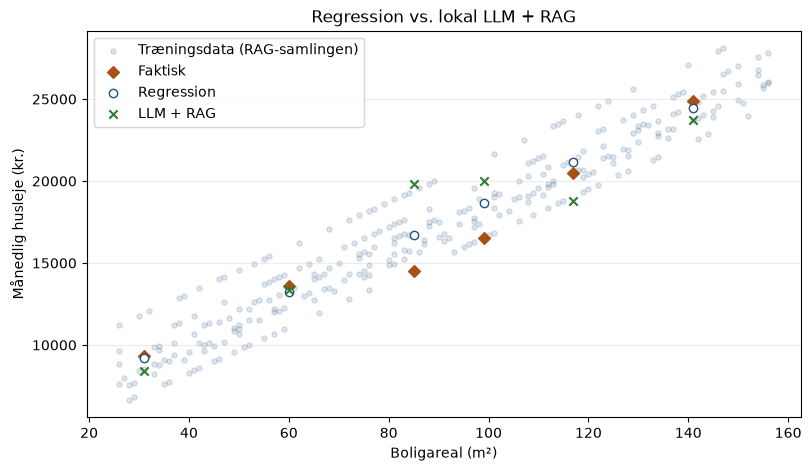

In [9]:
test_sorted = sorted(test, key=lambda row: float(row["area_m2"]))
areas = [float(row["area_m2"]) for row in test_sorted]
actuals = [float(row["monthly_rent_dkk"]) for row in test_sorted]

fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
ax.scatter([float(row["area_m2"]) for row in train], [float(row["monthly_rent_dkk"]) for row in train],
           color="#245285", alpha=0.15, s=14, label="Træningsdata (RAG-samlingen)")
ax.scatter(areas, actuals, color="#a95015", marker="D", zorder=3, label="Faktisk")
ax.scatter(areas, [regression[row["area_m2"]] for row in test_sorted], facecolors="white",
           edgecolors="#245285", zorder=3, label="Regression")
ax.scatter(areas, [llm_rag[row["area_m2"]] for row in test_sorted], color="#2e7d32", marker="x",
           zorder=3, label="LLM + RAG")
ax.set(title="Regression vs. lokal LLM + RAG", xlabel="Boligareal (m²)", ylabel="Månedlig husleje (kr.)")
ax.grid(axis="y", alpha=0.24)
ax.legend()
plt.show()

## 6. Kort opsummering

Diskussionen af resultatet står i `../README.md`: hvorfor metoderne giver forskellige svar, om RAG hjalp, og hvornår en specialiseret model er at foretrække. Den fulde retrieval-log med prompts og rå svar ligger i `retrieval_log.md`.